<a href="https://colab.research.google.com/github/Chaimakhalsi/Exam_Git_Khalsi_Chaima/blob/main/Copy_of_personne1_donnees_manifeste_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Personne 1 : données et manifeste
**Jeu de données :** *Fruits fresh and rotten for classification* (Sriram Reddy Kalluri, Kaggle) avec 6 classes.

Ce notebook couvre toute la partie « Données » :

1. Téléchargement et repérage de `train/` et `test/` (on ne garde qu'une copie de l'arborescence)
2. Comptage des fichiers lisibles par classe et par partition
3. Visualisation d'exemples et vérification des étiquettes numériques
4. Doublons exacts (MD5) et variantes proches (pHash), regroupés en **familles**
5. Manifeste CSV : chemin relatif, classe, partition, famille
6. Split train/validation (≈ 20 %), équilibré par classe et groupé par famille, sans aucune famille du test
7. Journal des cas ambigus
8. Brouillon de la section « Données » du rapport

**Fichiers produits dans `outputs/` :** `manifeste.csv`, `split_config.json`, `labels.json`, `effectifs.csv`, `doublons_exacts.csv`, `paires_proches.csv`, `familles.csv`, `journal_cas_ambigus.csv`, `rapport_section_donnees.md` et `figures/*.png`.

> Dans Colab : *Exécution → Tout exécuter*. Pour que le journal manuel et les sorties survivent à la fin de la session, mets `SAUVER_SUR_DRIVE = True` dans la cellule suivante.

## 0. Configuration

In [ ]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imagehash", "kagglehub"], check=False)

import os, re, io, json, hashlib, random, datetime
from pathlib import Path
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fftpack import dct
from sklearn.model_selection import StratifiedGroupKFold
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x
try:
    from IPython.display import display, Markdown
except ImportError:
    display = print; Markdown = str

# ----------------------------- Paramètres -----------------------------------
SEED = 42
PHASH_SEUIL = 4               # distance de Hamming max (sur 64 bits) pour « variante proche »
PHASH_SEUIL_MEME_CLASSE = 6   # seuil plus large quand les deux images ont la même classe
                              # (contrôle visuel : à d = 6, les faux liens relient toujours des classes différentes)
IGNORER_COINS_NOIRS = True    # exclure de la comparaison pHash les copies tournées/translatées
                              # (leurs coins noirs créent de faux liens ; elles sont reliées par leur nom)
MOTIF_COINS_NOIRS = r"^(rotated|rotation|translat)"
INVARIANCE_DIEDRALE = False   # True = comparer aussi les versions tournées/retournées (crée de faux liens
                              # sur ce jeu : fruits ronds sur fond blanc ; les retournements sont déjà
                              # reliés par le nom de fichier)
UTILISER_NOMS_FICHIERS = True # relier « rotated_by_15_xxx.png » à « xxx.png » (augmentations)
EXCLURE_CONFLITS = True       # retirer de train/val les familles qui mélangent plusieurs classes
VAL_FRACTION = 0.20
# MODE_SPLIT :
#  "test_kaggle" = consigne : on garde le test officiel et on retire du train les familles du test
#  "regrouper"   = on refait tout le découpage par famille (nouveau test ≈ TEST_FRACTION des images)
MODE_SPLIT = "test_kaggle"
TEST_FRACTION = 0.20
RECALCULER = False            # True = refaire le calcul des hash même si un cache existe
SAUVER_SUR_DRIVE = False      # True = tout écrire dans Google Drive (persistant)
# ----------------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED)

CLASSES = ["freshapples", "freshbanana", "freshoranges",
           "rottenapples", "rottenbanana", "rottenoranges"]
LABEL_MAP = {c: i for i, c in enumerate(CLASSES)}
PARTITIONS = ["train", "test"]
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".webp", ".tif", ".tiff"}
FORMATS_TF = {"PNG", "JPEG", "BMP", "GIF"}   # formats que tf.io.decode_image sait lire

def espece(c):
    return {"apples": "pomme", "banana": "banane", "oranges": "orange"}[c.replace("fresh", "").replace("rotten", "")]
def etat(c):
    return "sain" if c.startswith("fresh") else "pourri"

if SAUVER_SUR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path("/content/drive/MyDrive/projet_fruits/outputs")
else:
    OUT = Path("outputs")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Style des figures : grille discrète, une couleur fixe par partition
COULEURS = {"train": "#2a78d6", "val": "#1baf7a", "test": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e4e3dd", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

def md_table(df, index=True):
    """Tableau Markdown sans dépendance externe."""
    d = df.reset_index() if index else df
    lignes = ["| " + " | ".join(map(str, d.columns)) + " |",
              "|" + "|".join(["---"] * len(d.columns)) + "|"]
    lignes += ["| " + " | ".join(map(str, r)) + " |" for r in d.itertuples(index=False)]
    return "\n".join(lignes)

print("Sorties dans :", OUT.resolve())

Sorties dans : /content/outputs


## 1. Téléchargement et repérage de train/test
`kagglehub` télécharge le jeu public. S'il demande une authentification : *Kaggle → Settings → API → Create New Token*, puis ajoute `KAGGLE_USERNAME` et `KAGGLE_KEY` dans les *Secrets* Colab (icône 🔑) ou en variables d'environnement.

L'archive Kaggle contient **une copie imbriquée de l'arborescence** (`dataset/dataset/...`). La cellule suivante trouve toutes les copies, vérifie si elles sont identiques et n'en garde qu'une.

In [ ]:
if os.environ.get("FRUITS_DATA_DIR"):           # chemin local déjà téléchargé
    RAW_ROOT = Path(os.environ["FRUITS_DATA_DIR"])
else:
    import kagglehub
    RAW_ROOT = Path(kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification"))
print("Archive téléchargée dans :", RAW_ROOT)

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Archive téléchargée dans : /kaggle/input/fruits-fresh-and-rotten-for-classification


In [ ]:
def sous_dossier(d, nom):
    """Sous-dossier `nom` de `d`, sans tenir compte de la casse (None s'il n'existe pas)."""
    for p in d.iterdir():
        if p.is_dir() and p.name.lower().strip() == nom:
            return p
    return None

def est_racine(d):
    for part in PARTITIONS:
        dp = sous_dossier(d, part)
        if dp is None or any(sous_dossier(dp, c) is None for c in CLASSES):
            return False
    return True

def signature(racine):
    """Liste triée (chemin relatif, taille) des fichiers de train/ et test/."""
    sig = []
    for part in PARTITIONS:
        dp = sous_dossier(racine, part)
        sig += [(f.relative_to(racine).as_posix().lower(), f.stat().st_size)
                for f in dp.rglob("*") if f.is_file()]
    return sorted(sig)

candidats = [RAW_ROOT] + sorted(p for p in RAW_ROOT.rglob("*") if p.is_dir())
COPIES = [d for d in candidats if est_racine(d)]
assert COPIES, "Aucun dossier contenant train/ et test/ avec les 6 classes n'a été trouvé."

sigs = {d: signature(d) for d in COPIES}
tab = pd.DataFrame({
    "copie": [d.relative_to(RAW_ROOT).as_posix() or "." for d in COPIES],
    "profondeur": [len(d.relative_to(RAW_ROOT).parts) for d in COPIES],
    "nb_fichiers": [len(sigs[d]) for d in COPIES],
})
display(tab)

# On garde la copie la moins profonde ; à égalité, celle qui a le plus de fichiers
DATA_ROOT = min(COPIES, key=lambda d: (len(d.relative_to(RAW_ROOT).parts), -len(sigs[d])))
COPIES_IDENTIQUES = all(sigs[d] == sigs[DATA_ROOT] for d in COPIES)
SOUS_DOSSIER_RACINE = DATA_ROOT.relative_to(RAW_ROOT).as_posix() or "."
print(f"{len(COPIES)} copie(s) trouvée(s). Copies identiques : {COPIES_IDENTIQUES}")
print("Copie retenue (DATA_ROOT) :", DATA_ROOT)
if not COPIES_IDENTIQUES:
    print("⚠️ Les copies diffèrent : compare-les à la main avant de continuer.")

,copie,profondeur,nb_fichiers
0,dataset,1,13599
1,dataset/dataset,2,13599


2 copie(s) trouvée(s). Copies identiques : True
Copie retenue (DATA_ROOT) : /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset


## 2. Lecture de toutes les images : lisibilité, MD5, pHash
Pour chaque fichier, on calcule :
- la **lisibilité** (le fichier s'ouvre, se décode entièrement et son format est lisible par TensorFlow),
- le **MD5** des octets, pour les doublons exacts,
- le **pHash** sur 64 bits, ainsi que ses 8 variantes (rotations de 90° et retournements). Le jeu contient des images augmentées par retournement, que le pHash simple ne repère pas.

Le résultat est mis en cache dans `caracteristiques.csv`.

In [ ]:
rows = []
for part in PARTITIONS:
    dp = sous_dossier(DATA_ROOT, part)
    for cls in CLASSES:
        for f in sorted(sous_dossier(dp, cls).rglob("*")):
            if f.is_file():
                rows.append({"chemin_relatif": f.relative_to(DATA_ROOT).as_posix(),
                             "classe": cls, "partition": part})
fichiers = pd.DataFrame(rows)
print(len(fichiers), "fichiers trouvés")

def phash64(gris32):
    """pHash 64 bits (même algorithme que imagehash.phash) sur une image 32x32 en niveaux de gris."""
    d = dct(dct(gris32.astype(float), axis=0), axis=1)[:8, :8]
    bits = (d > np.median(d)).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)

def analyser(chemin_rel):
    p = DATA_ROOT / chemin_rel
    r = {"lisible": False, "erreur": "", "format": "", "mode": "", "largeur": np.nan,
         "hauteur": np.nan, "md5": "", "phash": "", "phash_variantes": ""}
    if p.suffix.lower() not in IMG_EXT:
        r["erreur"] = "extension non image"
        return r
    try:
        data = p.read_bytes()
        r["md5"] = hashlib.md5(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            im.load()                                   # force le décodage complet
            r["format"], r["mode"] = im.format, im.mode
            r["largeur"], r["hauteur"] = im.size
            gris = np.asarray(im.convert("RGB").convert("L").resize((32, 32), Image.LANCZOS))
        if r["format"] not in FORMATS_TF:
            r["erreur"] = f"format {r['format']} non décodable par TensorFlow"
            return r
        variantes = [np.rot90(g, k) for g in (gris, np.fliplr(gris)) for k in range(4)]
        hs = [f"{phash64(v):016x}" for v in variantes]
        r["phash"], r["phash_variantes"] = hs[0], ";".join(hs)
        r["lisible"] = True
    except Exception as e:
        r["erreur"] = f"{type(e).__name__}: {e}"
    return r

CACHE = OUT / "caracteristiques.csv"
if CACHE.exists() and not RECALCULER:
    cache = pd.read_csv(CACHE, dtype={"md5": str, "phash": str, "phash_variantes": str}, keep_default_na=False)
    if set(cache.chemin_relatif) == set(fichiers.chemin_relatif):
        df = fichiers.merge(cache.drop(columns=["classe", "partition"]), on="chemin_relatif")
        df["lisible"] = df["lisible"].astype(str).eq("True")
        for col in ("largeur", "hauteur"):
            df[col] = pd.to_numeric(df[col], errors="coerce")
        print("Cache réutilisé.")
    else:
        CACHE.unlink(); df = None
else:
    df = None
if df is None:
    with ThreadPoolExecutor(max_workers=min(8, (os.cpu_count() or 2) * 2)) as ex:
        res = list(tqdm(ex.map(analyser, fichiers.chemin_relatif), total=len(fichiers)))
    df = pd.concat([fichiers, pd.DataFrame(res)], axis=1)
    df.to_csv(CACHE, index=False)

df["label"] = df.classe.map(LABEL_MAP)
df["espece"] = df.classe.map(espece)
df["etat"] = df.classe.map(etat)
print(f"Lisibles : {df.lisible.sum()} / {len(df)}")

13599 fichiers trouvés
Cache réutilisé.
Lisibles : 13599 / 13599


## 3. Effectifs par classe et par partition

partition,train,test,total
classe,,,
freshapples,1693,395,2088
freshbanana,1581,381,1962
freshoranges,1466,388,1854
rottenapples,2342,601,2943
rottenbanana,2224,530,2754
rottenoranges,1595,403,1998
TOTAL,10901,2698,13599



Fichiers illisibles ou ignorés : 0


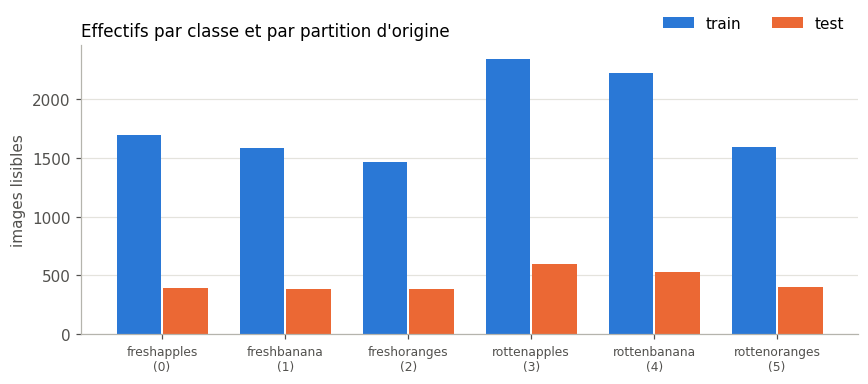

In [ ]:
ok = df[df.lisible].reset_index(drop=True)
effectifs = (pd.crosstab(ok.classe, ok.partition)
             .reindex(index=CLASSES, columns=PARTITIONS, fill_value=0))
effectifs["total"] = effectifs.sum(axis=1)
effectifs.loc["TOTAL"] = effectifs.sum()
effectifs.index.name = "classe"
display(effectifs)
effectifs.to_csv(OUT / "effectifs.csv")

illisibles = df[~df.lisible][["chemin_relatif", "classe", "partition", "erreur"]]
print(f"\nFichiers illisibles ou ignorés : {len(illisibles)}")
if len(illisibles):
    display(illisibles)

# Figure : effectifs lisibles par classe (barres groupées train/test)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(CLASSES)); w = 0.38
for k, part in enumerate(PARTITIONS):
    ax.bar(x + (k - 0.5) * w, effectifs.loc[CLASSES, part], width=w - 0.02,
           color=COULEURS[part], label=part)
ax.set_xticks(x, [f"{c}\n({LABEL_MAP[c]})" for c in CLASSES], fontsize=8)
ax.set_ylabel("images lisibles")
ax.set_title("Effectifs par classe et par partition d'origine", loc="left")
ax.legend(ncols=2, loc="lower right", bbox_to_anchor=(1, 1.0))
fig.tight_layout(); fig.savefig(FIG / "effectifs_classes.png", bbox_inches="tight"); plt.show()

## 4. Visualisation et vérification des étiquettes
Les étiquettes numériques suivent l'**ordre alphabétique des dossiers**, comme `tf.keras.utils.image_dataset_from_directory`. On vérifie cet ordre, puis on regarde quelques images de chaque classe : chaque ligne doit montrer l'espèce et l'état écrits dans son titre.

,label,dossier,espece,etat
0,0,freshapples,pomme,sain
1,1,freshbanana,banane,sain
2,2,freshoranges,orange,sain
3,3,rottenapples,pomme,pourri
4,4,rottenbanana,banane,pourri
5,5,rottenoranges,orange,pourri


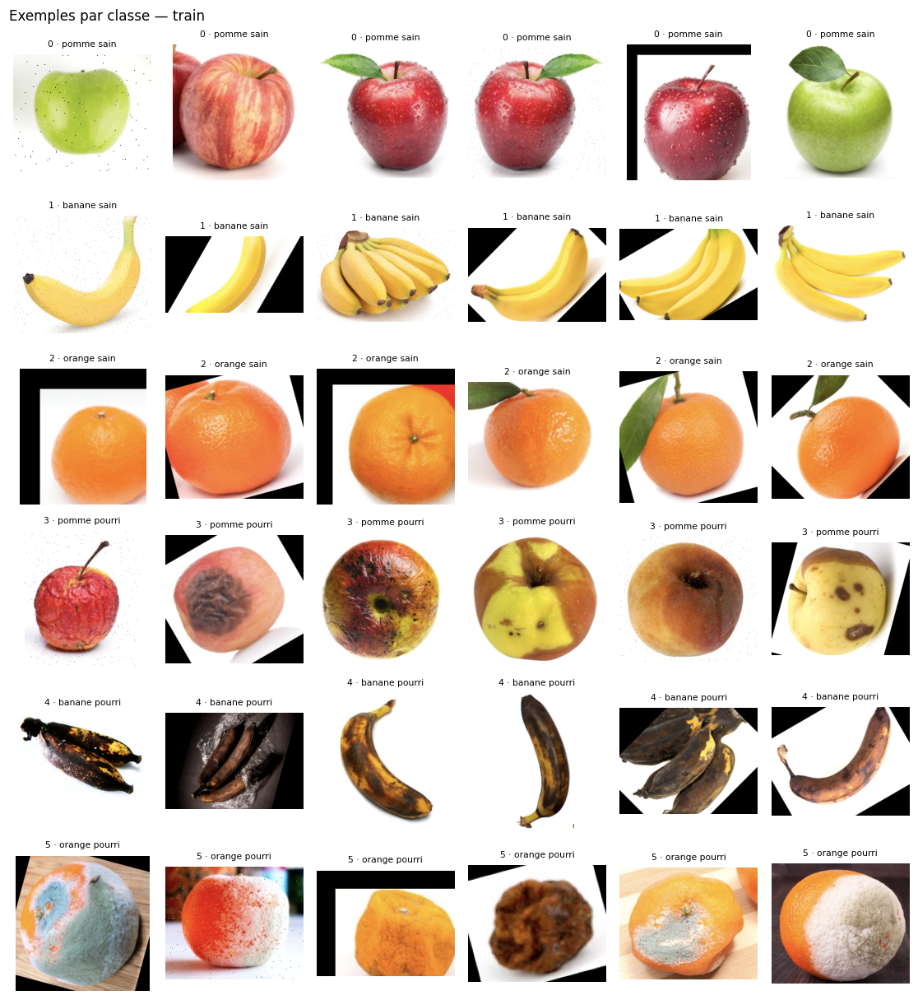

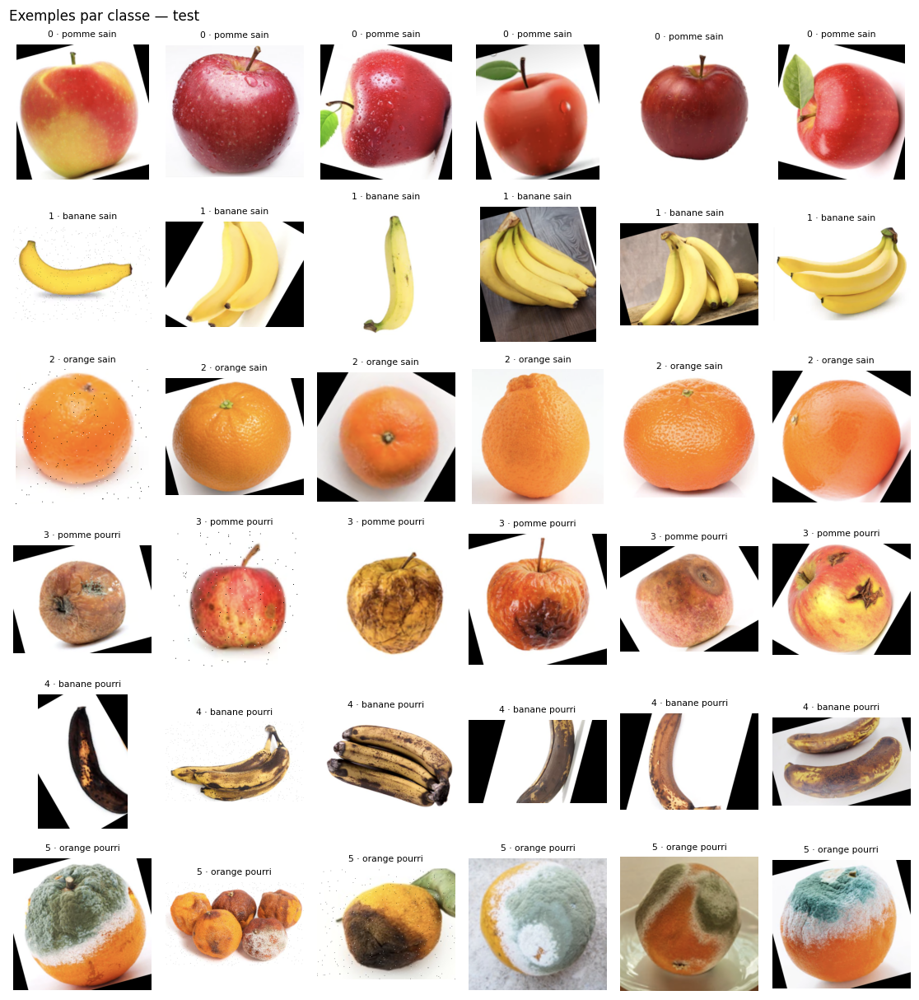

In [ ]:
assert CLASSES == sorted(CLASSES), "L'ordre des classes ne suit pas l'ordre alphabétique de Keras"
for c in CLASSES:   # le nom du dossier contient bien l'espèce et l'état
    assert ("fresh" in c) == (etat(c) == "sain") and espece(c)
correspondance = pd.DataFrame({"label": [LABEL_MAP[c] for c in CLASSES], "dossier": CLASSES,
                               "espece": [espece(c) for c in CLASSES], "etat": [etat(c) for c in CLASSES]})
display(correspondance)
with open(OUT / "labels.json", "w") as f:
    json.dump({"classes": CLASSES, "label_map": LABEL_MAP,
               "espece": {c: espece(c) for c in CLASSES}, "etat": {c: etat(c) for c in CLASSES}},
              f, indent=2, ensure_ascii=False)

def mosaique(chemins, titres=None, ncols=6, taille=1.7, titre=None, fichier=None):
    n = len(chemins); nrows = max(1, int(np.ceil(n / ncols)))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * taille, nrows * taille * 1.1))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for k, (ax, p) in enumerate(zip(np.atleast_1d(axes).ravel(), chemins)):
        with Image.open(DATA_ROOT / p) as im:
            ax.imshow(im.convert("RGB"))
        if titres: ax.set_title(titres[k], fontsize=7)
    if titre: fig.suptitle(titre, x=0.01, ha="left", fontsize=11)
    fig.tight_layout()
    if fichier: fig.savefig(FIG / fichier, bbox_inches="tight")
    plt.show()

N_PAR_CLASSE = 6
for part in PARTITIONS:
    chemins, titres = [], []
    for c in CLASSES:
        ech = ok[(ok.classe == c) & (ok.partition == part)].sample(
            min(N_PAR_CLASSE, ((ok.classe == c) & (ok.partition == part)).sum()), random_state=SEED)
        chemins += ech.chemin_relatif.tolist()
        titres += [f"{LABEL_MAP[c]} · {espece(c)} {etat(c)}"] * len(ech)
    mosaique(chemins, titres, ncols=N_PAR_CLASSE, titre=f"Exemples par classe — {part}",
             fichier=f"exemples_{part}.png")

## 5. Doublons exacts (MD5)
On classe chaque groupe de doublons selon trois cas :
- **même partition, même classe** : copie simple ;
- **train ↔ test** : fuite de données à retirer du train ;
- **classes différentes** : conflit d'étiquette, à reporter dans le journal.

In [ ]:
grp = ok.groupby("md5")
doublons = ok[ok.md5.map(grp.size()) > 1].copy()
resume_md5 = doublons.groupby("md5").agg(
    n=("chemin_relatif", "size"), classes=("classe", lambda s: ",".join(sorted(set(s)))),
    partitions=("partition", lambda s: ",".join(sorted(set(s)))),
    exemple=("chemin_relatif", "first")).reset_index()

def type_doublon(r):
    if "," in r.classes: return "conflit de classe"
    if "," in r.partitions: return "train ↔ test"
    return "même partition"
resume_md5["type"] = resume_md5.apply(type_doublon, axis=1) if len(resume_md5) else []
resume_md5.to_csv(OUT / "doublons_exacts.csv", index=False)

N_MD5_GROUPES = len(resume_md5)
N_MD5_FICHIERS = int(resume_md5.n.sum()) if len(resume_md5) else 0
N_MD5_REDONDANTS = N_MD5_FICHIERS - N_MD5_GROUPES
print(f"{N_MD5_GROUPES} groupes de doublons exacts, {N_MD5_FICHIERS} fichiers concernés "
      f"({N_MD5_REDONDANTS} copies en trop)")
display(resume_md5.groupby("type").agg(groupes=("md5", "size"), fichiers=("n", "sum")) if len(resume_md5) else "aucun")

0 groupes de doublons exacts, 0 fichiers concernés (0 copies en trop)


'aucun'

## 6. Variantes proches (pHash)
Deux images sont des **variantes proches** si la distance de Hamming entre leurs pHash est ≤ `PHASH_SEUIL_MEME_CLASSE` (même classe) ou ≤ `PHASH_SEUIL` (classes différentes). Si `INVARIANCE_DIEDRALE = True`, on prend la distance minimale sur les 8 orientations (rotations de 90° et retournements). C'est désactivé par défaut : sur ce jeu (fruits ronds sur fond blanc), cela relie à tort des fruits différents, et les retournements sont déjà repérés par le nom de fichier. Le calcul est vectorisé avec NumPy et prend environ une minute pour 13 000 images.

Les copies **tournées ou translatées** (préfixes `rotated_by_…`, `translation_…`) sont exclues de cette comparaison quand `IGNORER_COINS_NOIRS = True`. Leurs coins noirs rapprochent à tort des fruits différents, et elles sont de toute façon rattachées à leur original par le nom de fichier (section 7).

La cellule d'après affiche des paires juste **sous** le seuil et juste **au-dessus** : sers-t'en pour valider ou ajuster `PHASH_SEUIL`.

In [ ]:
N = len(ok)
H = np.array([int(h, 16) for h in ok.phash], dtype=np.uint64)
V = np.array([[int(x, 16) for x in s.split(";")] for s in ok.phash_variantes], dtype=np.uint64)
if not INVARIANCE_DIEDRALE:
    V = V[:, :1]

if hasattr(np, "bitwise_count"):
    popcount = np.bitwise_count
else:
    _LUT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def popcount(x):
        return _LUT[x.view(np.uint8).reshape(*x.shape, 8)].sum(-1)

SEUIL_AFFICHAGE = max(PHASH_SEUIL, PHASH_SEUIL_MEME_CLASSE) + 2   # paires un peu au-dessus, pour le contrôle visuel
paires = {}
B = 64
for s in tqdm(range(0, N, B), desc="pHash"):
    blk = H[s:s + B]
    d = popcount(blk[:, None, None] ^ V[None, :, :]).min(axis=2)    # (B, N)
    ii, jj = np.nonzero(d <= SEUIL_AFFICHAGE)
    for i_loc, j in zip(ii, jj):
        i = s + i_loc
        if i == j: continue
        cle = (min(i, j), max(i, j))
        dist = int(d[i_loc, j])
        if dist < paires.get(cle, 99):
            paires[cle] = dist

paires_df = pd.DataFrame([(i, j, dd) for (i, j), dd in paires.items()], columns=["i", "j", "distance"])
if len(paires_df):
    for col, src in (("a", "i"), ("b", "j")):
        for champ in ("chemin_relatif", "classe", "partition", "md5"):
            paires_df[f"{champ}_{col}"] = ok[champ].values[paires_df[src]]
    paires_df["meme_md5"] = paires_df.md5_a == paires_df.md5_b
    paires_df["meme_classe"] = paires_df.classe_a == paires_df.classe_b
    paires_df["train_test"] = paires_df.partition_a != paires_df.partition_b
coins_noirs = ok.chemin_relatif.map(lambda p: bool(re.match(MOTIF_COINS_NOIRS, Path(p).stem, re.I))).values
N_COINS_NOIRS = int(coins_noirs.sum())
if len(paires_df):
    paires_df["eligible"] = ~(coins_noirs[paires_df.i.values] | coins_noirs[paires_df.j.values]) \
        if IGNORER_COINS_NOIRS else True
print(f"Images exclues de la comparaison pHash (coins noirs) : {N_COINS_NOIRS if IGNORER_COINS_NOIRS else 0}")
if len(paires_df):
    paires_df["seuil"] = np.where(paires_df.meme_classe, PHASH_SEUIL_MEME_CLASSE, PHASH_SEUIL)
    paires_df["accepte"] = paires_df.eligible & (paires_df.distance <= paires_df.seuil)
proches = paires_df[paires_df.accepte] if len(paires_df) else paires_df
proches_non_exactes = proches[~proches.meme_md5] if len(proches) else proches
proches.drop(columns=["i", "j"]).to_csv(OUT / "paires_proches.csv", index=False)

N_PAIRES_PROCHES = len(proches_non_exactes)
N_PAIRES_TRAIN_TEST = int(proches_non_exactes.train_test.sum()) if len(proches_non_exactes) else 0
N_PAIRES_CONFLIT = int((~proches_non_exactes.meme_classe).sum()) if len(proches_non_exactes) else 0
print(f"Variantes proches (hors doublons exacts ; d ≤ {PHASH_SEUIL_MEME_CLASSE} même classe, "
      f"d ≤ {PHASH_SEUIL} entre classes) : {N_PAIRES_PROCHES} paires")
print(f"  dont entre train et test : {N_PAIRES_TRAIN_TEST}")
print(f"  dont entre classes différentes : {N_PAIRES_CONFLIT}")
if len(paires_df):
    display(paires_df[~paires_df.meme_md5 & paires_df.eligible].distance.value_counts().sort_index().rename("nb paires"))

pHash:   0%|          | 0/213 [00:00<?, ?it/s]

Images exclues de la comparaison pHash (coins noirs) : 9066
Variantes proches (hors doublons exacts ; d ≤ 6 même classe, d ≤ 4 entre classes) : 1827 paires
  dont entre train et test : 587
  dont entre classes différentes : 3


,nb paires
distance,
0,1217
2,319
4,102
6,233
8,762


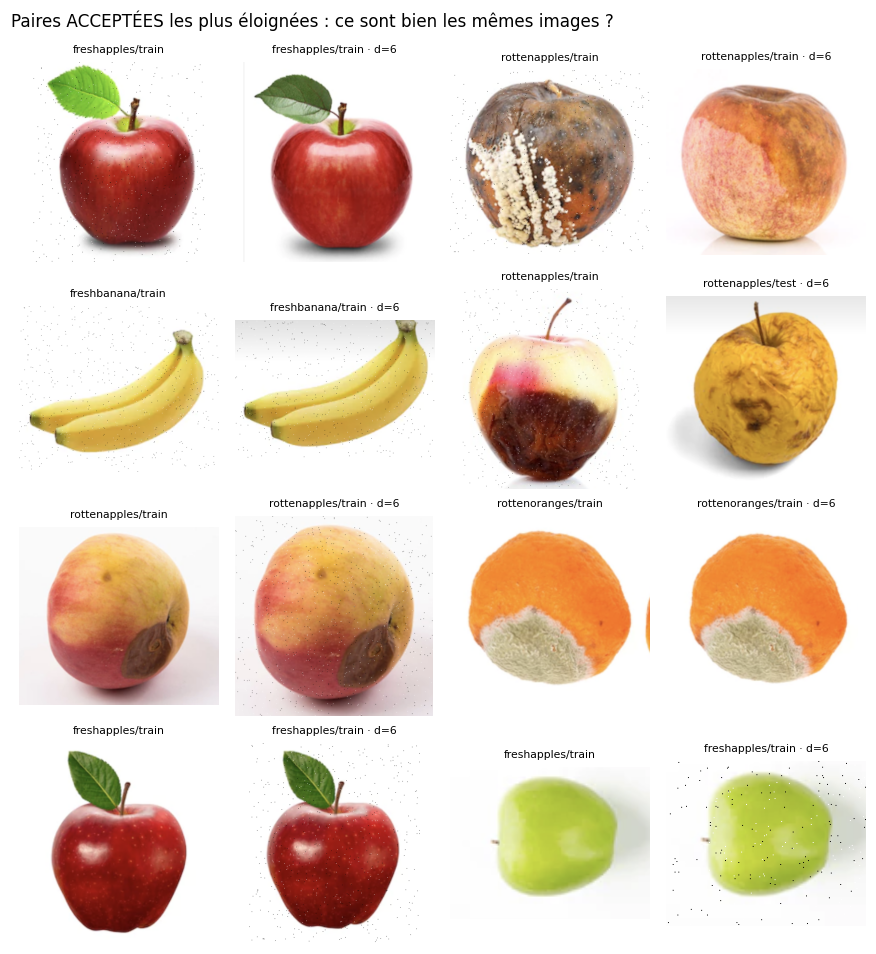

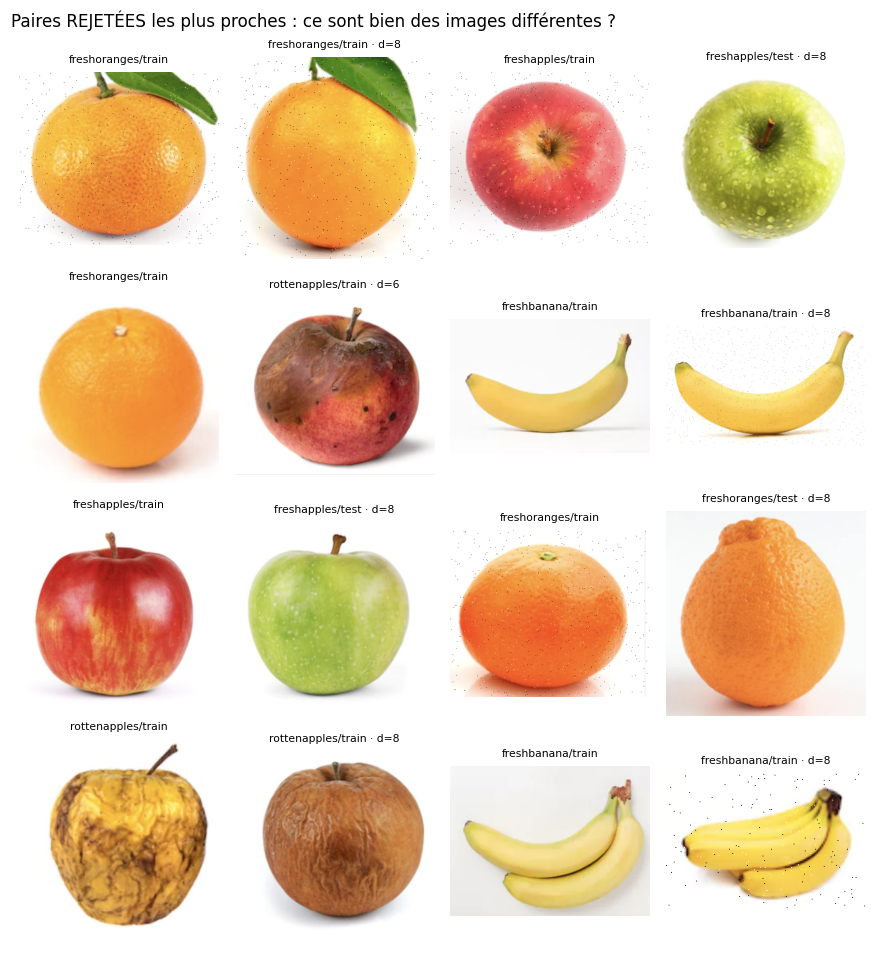

In [ ]:
def montrer_paires(sel, titre, n=6):
    sel = sel.sample(min(n, len(sel)), random_state=SEED) if len(sel) else sel
    if not len(sel):
        print(titre, ": aucune paire"); return
    chemins, titres = [], []
    for r in sel.itertuples():
        chemins += [r.chemin_relatif_a, r.chemin_relatif_b]
        titres += [f"{r.classe_a}/{r.partition_a}", f"{r.classe_b}/{r.partition_b} · d={r.distance}"]
    mosaique(chemins, titres, ncols=4, taille=2.0, titre=titre)

if len(paires_df):
    nx = paires_df[~paires_df.meme_md5 & paires_df.eligible]
    acc, rej = nx[nx.accepte], nx[~nx.accepte]
    montrer_paires(acc[acc.distance >= acc.seuil - 1], "Paires ACCEPTÉES les plus éloignées : ce sont bien les mêmes images ?", n=8)
    montrer_paires(rej[rej.distance <= rej.seuil + 2], "Paires REJETÉES les plus proches : ce sont bien des images différentes ?", n=8)

## 7. Liens par nom de fichier (augmentations)
Le jeu Kaggle contient des images augmentées dont le nom reprend celui de l'original avec un préfixe (par exemple `rotated_by_15_<original>.png`). Une rotation de 15° ne se repère **pas** au pHash, mais le nom du fichier la trahit.

On affiche d'abord les préfixes les plus fréquents pour vérifier que l'expression régulière `PREFIXES_AUG` les couvre bien. Adapte-la si besoin.

In [ ]:
noms = ok.chemin_relatif.map(lambda p: Path(p).stem)
premier_mot = noms.map(lambda s: re.split(r"[_\s\-]", s, maxsplit=1)[0].lower())
print("Premiers mots les plus fréquents dans les noms de fichiers :")
display(premier_mot.value_counts().head(15).rename("nb fichiers"))

PREFIXES_AUG = re.compile(
    r"^(?:(?:rotated_by_-?\d+|rotated_?-?\d*|rotation_?-?\d*|translat[a-z]*|"
    r"vertical_?flip[a-z]*|horizontal_?flip[a-z]*|flipped|flip|"
    r"salt_?and_?pep+er[a-z]*|noise[a-z]*|zoom[a-z]*|shear[a-z]*|blur[a-z]*|bright[a-z]*)[_\s-])+",
    re.IGNORECASE)
SUFFIXES_COPIE = re.compile(r"(?:[\s_-]*\(\d+\)|[\s_-]+(?:copy|copie)\d*)$", re.IGNORECASE)

def radical(stem):
    return SUFFIXES_COPIE.sub("", PREFIXES_AUG.sub("", stem)).strip().lower()

ok["radical"] = noms.map(radical)
ok["a_prefixe"] = noms.map(lambda s: bool(PREFIXES_AUG.match(s)))
informatif = ok.radical.str.len().ge(6) & ~ok.radical.str.fullmatch(r"\d+")   # évite « 1.png », « img.png »…
cle = ok.classe + "|" + ok.radical
taille_cle = cle.map(cle.value_counts())
N_AUG_PREFIXE = int(ok.a_prefixe.sum())
N_PHOTOS_ORIGINE = ok.radical.nunique()
N_PHOTOS_COMMUNES = len(set(ok.loc[ok.partition == "train", "radical"]) & set(ok.loc[ok.partition == "test", "radical"]))
print(f"Photos d'origine distinctes (radicaux) : {N_PHOTOS_ORIGINE}, dont {N_PHOTOS_COMMUNES} "
      f"présentes à la fois dans train et test (découpage officiel)")
print(f"Fichiers avec préfixe d'augmentation : {N_AUG_PREFIXE}")
print(f"Fichiers reliables par radical (même classe, radical partagé) : "
      f"{int((informatif & (taille_cle > 1)).sum()) if UTILISER_NOMS_FICHIERS else 0}")
display(ok.loc[ok.a_prefixe, ["chemin_relatif", "radical"]].head(8))

Premiers mots les plus fréquents dans les noms de fichiers :


,nb fichiers
chemin_relatif,
rotated,7555
screen,1511
saltandpepper,1511
translation,1511
vertical,1511


Photos d'origine distinctes (radicaux) : 1511, dont 1310 présentes à la fois dans train et test (découpage officiel)
Fichiers avec préfixe d'augmentation : 12088
Fichiers reliables par radical (même classe, radical partagé) : 13599


,chemin_relatif,radical
182,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 4.59.36 pm
183,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 4.59.44 pm
184,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 4.59.57 pm
185,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 5.00.03 pm
186,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 5.00.12 pm
187,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 5.00.18 pm
188,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 5.00.26 pm
189,train/freshapples/rotated_by_15_Screen Shot 20...,screen shot 2018-06-08 at 5.00.50 pm


## 8. Familles (union-find)
Une **famille** regroupe toutes les images reliées, directement ou de proche en proche, par un même MD5, un pHash proche ou un même radical de nom. Deux images d'une même famille ne doivent jamais se retrouver dans deux partitions différentes.

Fusions effectives par source : {'pHash': 1640, 'nom de fichier': 10537}
1422 familles pour 13599 images (1422 de taille > 1)
Taille : médiane 9, max 54
Familles présentes dans train ET test : 1240
Familles qui mélangent plusieurs classes : 1


,taille,classes,partitions,exemple,multi_classe,train_et_test
famille,,,,,,
F00340,54,"freshbanana,rottenbanana","test,train",train/freshbanana/Screen Shot 2018-06-12 at 9....,True,True
F00302,45,freshbanana,"test,train",train/freshbanana/Screen Shot 2018-06-12 at 9....,False,True
F00287,36,freshbanana,"test,train",train/freshbanana/Screen Shot 2018-06-12 at 9....,False,True
F00003,36,freshapples,"test,train",train/freshapples/Screen Shot 2018-06-08 at 5....,False,True
F00654,36,rottenapples,"test,train",train/rottenapples/Screen Shot 2018-06-07 at 2...,False,True
F00231,36,freshbanana,"test,train",train/freshbanana/Screen Shot 2018-06-12 at 10...,False,True
F00720,27,rottenapples,"test,train",train/rottenapples/Screen Shot 2018-06-07 at 3...,False,True
F00637,27,rottenapples,train,train/rottenapples/Screen Shot 2018-06-07 at 2...,False,False


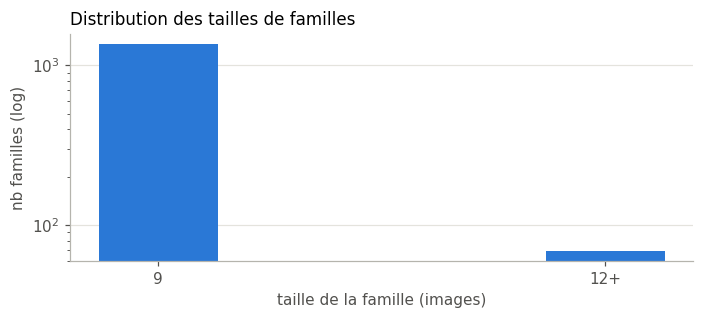

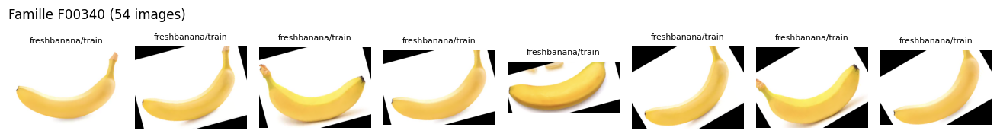

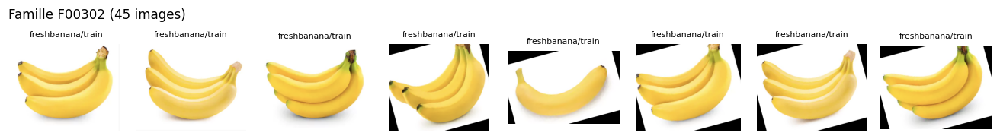

In [ ]:
parent = np.arange(N)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra == rb: return 0
    parent[max(ra, rb)] = min(ra, rb); return 1

liens = Counter()
for _, idx in ok.groupby("md5").groups.items():
    idx = list(idx)
    for k in idx[1:]: liens["MD5"] += union(idx[0], k)
for r in (proches.itertuples() if len(proches) else []):
    liens["pHash"] += union(r.i, r.j)
if UTILISER_NOMS_FICHIERS:
    for _, idx in ok[informatif].groupby(cle[informatif]).groups.items():
        idx = list(idx)
        for k in idx[1:]: liens["nom de fichier"] += union(idx[0], k)
print("Fusions effectives par source :", dict(liens))

racines = np.array([find(i) for i in range(N)])
ordre = {r: k for k, r in enumerate(dict.fromkeys(racines))}
ok["famille"] = [f"F{ordre[r]:05d}" for r in racines]

fam = ok.groupby("famille").agg(
    taille=("chemin_relatif", "size"),
    classes=("classe", lambda s: ",".join(sorted(set(s)))),
    partitions=("partition", lambda s: ",".join(sorted(set(s)))),
    exemple=("chemin_relatif", "first"))
fam["multi_classe"] = fam.classes.str.contains(",")
fam["train_et_test"] = fam.partitions.str.contains(",")
fam.to_csv(OUT / "familles.csv")

N_FAMILLES = len(fam); N_FAM_MULTI = int((fam.taille > 1).sum())
N_FAM_TT = int(fam.train_et_test.sum()); N_FAM_CONFLIT = int(fam.multi_classe.sum())
print(f"{N_FAMILLES} familles pour {N} images ({N_FAM_MULTI} de taille > 1)")
print(f"Taille : médiane {fam.taille.median():.0f}, max {fam.taille.max()}")
print(f"Familles présentes dans train ET test : {N_FAM_TT}")
print(f"Familles qui mélangent plusieurs classes : {N_FAM_CONFLIT}")
if fam.taille.max() > 0.02 * N:
    print("⚠️ Une famille dépasse 2 % des images : chaînage probable, baisse PHASH_SEUIL.")
display(fam.sort_values("taille", ascending=False).head(8))

fig, ax = plt.subplots(figsize=(6.5, 3))
vc = fam.taille.clip(upper=12).value_counts().sort_index()
ax.bar(vc.index.astype(int), vc.values, width=0.8, color=COULEURS["train"])
ax.set_xticks(vc.index.astype(int), [str(i) if i < 12 else "12+" for i in vc.index.astype(int)])
ax.set_yscale("log"); ax.set_xlabel("taille de la famille (images)"); ax.set_ylabel("nb familles (log)")
ax.set_title("Distribution des tailles de familles", loc="left")
fig.tight_layout(); fig.savefig(FIG / "tailles_familles.png", bbox_inches="tight"); plt.show()

# Contrôle visuel : membres des plus grandes familles
for f_id in fam.sort_values("taille", ascending=False).head(2).index:
    m = ok[ok.famille == f_id].head(8)
    mosaique(m.chemin_relatif.tolist(), [f"{c}/{p}" for c, p in zip(m.classe, m.partition)],
             ncols=8, taille=1.5, titre=f"Famille {f_id} ({fam.loc[f_id, 'taille']} images)")

## 9. Split train / validation / test
On a deux modes possibles, réglés par `MODE_SPLIT` dans la configuration :

- **`"test_kaggle"`** (la consigne) : on garde la partition `test` officielle telle quelle, on retire du train les **familles présentes dans le test**, puis on découpe le reste en train et validation ;
- **`"regrouper"`** : on ignore le découpage officiel et on refait **tout** le découpage par famille. Le nouveau test fait environ `TEST_FRACTION` des images, puis le reste est découpé en train et validation.

Dans les deux cas, les familles qui mélangent plusieurs classes sont retirées si `EXCLURE_CONFLITS`, et chaque découpage utilise `StratifiedGroupKFold` : on garde le pli dont la proportion par classe est la plus proche de la cible.

Mode 'test_kaggle' — validation : pli 1 (écart max à 20% par classe : 3.1%)
✅ Aucune famille ni aucun MD5 partagé entre train, val et test.


split,train,val,test,exclu,% val
classe,,,,,
freshapples,198,54,395,1441,21.4
freshbanana,216,54,381,1311,20.0
freshoranges,225,54,388,1187,19.4
rottenapples,180,54,601,2108,23.1
rottenbanana,333,72,530,1819,17.8
rottenoranges,171,45,403,1379,20.8
TOTAL,1323,333,2698,9245,20.1


raison_exclusion
famille présente dans le test    9245
Name: count, dtype: int64


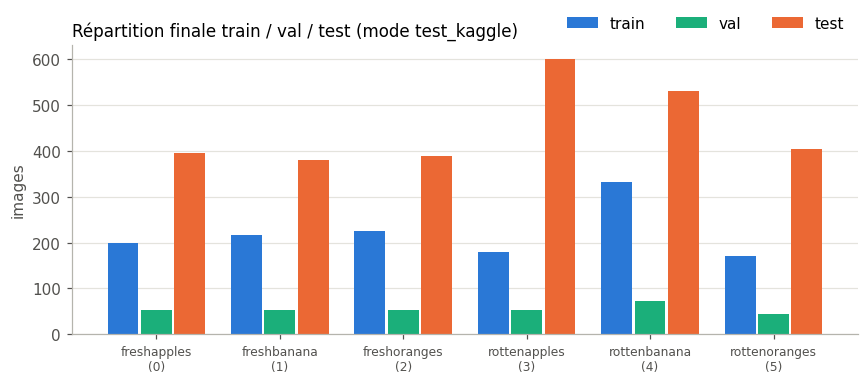

In [ ]:
fam_conflit = set(fam.index[fam.multi_classe])

def choisir_pli(pool, fraction):
    """Pli de StratifiedGroupKFold (groupé par famille) le plus proche de `fraction` dans chaque classe."""
    n = int(round(1 / fraction))
    meilleur = None
    for k, (_, iv) in enumerate(StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=SEED)
                                .split(pool, pool.label, groups=pool.famille)):
        frac = (pool.iloc[iv].classe.value_counts().reindex(CLASSES, fill_value=0)
                / pool.classe.value_counts().reindex(CLASSES))
        ecart = float((frac - fraction).abs().max())
        if meilleur is None or ecart < meilleur[1]:
            meilleur = (k, ecart, pool.index[iv])
    return meilleur, n

ok["split"] = "exclu"; ok["raison_exclusion"] = ""
m_conf_all = ok.famille.isin(fam_conflit) & EXCLURE_CONFLITS
PLI_TEST = ECART_TEST = None

if MODE_SPLIT == "test_kaggle":
    fam_test = set(ok.loc[ok.partition == "test", "famille"])
    ok.loc[ok.partition == "test", "split"] = "test"
    est_train = ok.partition == "train"
    m_fuite = est_train & ok.famille.isin(fam_test)
    ok.loc[m_fuite, "raison_exclusion"] = "famille présente dans le test"
    m_conf = est_train & ~m_fuite & m_conf_all
    ok.loc[m_conf, "raison_exclusion"] = "famille avec plusieurs classes"
    pool = ok[est_train & ~m_fuite & ~m_conf]
elif MODE_SPLIT == "regrouper":
    ok.loc[m_conf_all, "raison_exclusion"] = "famille avec plusieurs classes"
    pool0 = ok[~m_conf_all]
    (PLI_TEST, ECART_TEST, idx_test), _ = choisir_pli(pool0, TEST_FRACTION)
    ok.loc[idx_test, "split"] = "test"
    pool = pool0.drop(index=idx_test)
    print(f"Nouveau test : pli {PLI_TEST} (écart max à {TEST_FRACTION:.0%} par classe : {ECART_TEST:.1%})")
else:
    raise ValueError("MODE_SPLIT doit valoir 'test_kaggle' ou 'regrouper'")

(PLI_RETENU, ECART_MAX, idx_val), n_plis = choisir_pli(pool, VAL_FRACTION)
ok.loc[pool.index, "split"] = "train"
ok.loc[idx_val, "split"] = "val"
print(f"Mode {MODE_SPLIT!r} — validation : pli {PLI_RETENU} (écart max à {VAL_FRACTION:.0%} par classe : {ECART_MAX:.1%})")

# Vérifications : aucune famille partagée entre deux splits
fam_par_split = {s: set(ok.loc[ok.split == s, "famille"]) for s in ("train", "val", "test")}
assert not fam_par_split["train"] & fam_par_split["val"], "fuite train/val"
assert not fam_par_split["train"] & fam_par_split["test"], "fuite train/test"
assert not fam_par_split["val"] & fam_par_split["test"], "fuite val/test"
assert set(ok.loc[ok.split.isin(["train", "val"]), "md5"]).isdisjoint(set(ok.loc[ok.split == "test", "md5"]))
print("✅ Aucune famille ni aucun MD5 partagé entre train, val et test.")
if fam.taille.max() > 0.02 * N:
    print("⚠️ Une famille dépasse 2 % des images : vérifie la section 8 avant d'utiliser ce split.")

repartition = (pd.crosstab(ok.classe, ok.split).reindex(index=CLASSES, columns=["train", "val", "test", "exclu"], fill_value=0))
repartition.loc["TOTAL"] = repartition.sum()
repartition = repartition.astype(int)
repartition["% val"] = (100 * repartition.val / (repartition.train + repartition.val)).round(1)
repartition.index.name = "classe"
display(repartition)
print(ok[ok.split == "exclu"].raison_exclusion.value_counts())

fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.27
for k, s in enumerate(["train", "val", "test"]):
    ax.bar(np.arange(6) + (k - 1) * w, repartition.loc[CLASSES, s], width=w - 0.02, color=COULEURS[s], label=s)
ax.set_xticks(np.arange(6), [f"{c}\n({LABEL_MAP[c]})" for c in CLASSES], fontsize=8)
ax.set_ylabel("images"); ax.legend(ncols=3, loc="lower right", bbox_to_anchor=(1, 1.0))
ax.set_title(f"Répartition finale train / val / test (mode {MODE_SPLIT})", loc="left")
fig.tight_layout(); fig.savefig(FIG / "split_final.png", bbox_inches="tight"); plt.show()

## 10. Manifeste CSV
Une ligne par fichier, y compris les fichiers illisibles et exclus, pour garder la traçabilité. Les Personnes 2 à 4 filtrent sur `split`.

| colonne | contenu |
|---|---|
| `chemin_relatif` | chemin depuis `DATA_ROOT` (par exemple `train/freshapples/xxx.png`) |
| `classe`, `label` | nom du dossier et étiquette 0–5 |
| `espece`, `etat` | pomme / banane / orange, sain / pourri |
| `partition` | partition d'origine Kaggle (train / test) ; peut différer de `split` en mode `regrouper` |
| `famille` | identifiant de famille (`F00042`) |
| `split` | **train / val / test / exclu** |
| `raison_exclusion` | pourquoi l'image est exclue |

In [ ]:
man = df[["chemin_relatif", "classe", "label", "espece", "etat", "partition", "lisible", "erreur",
          "format", "largeur", "hauteur", "md5", "phash"]].merge(
    ok[["chemin_relatif", "famille", "split", "raison_exclusion"]], on="chemin_relatif", how="left")
man["famille"] = man.famille.fillna("")
man["split"] = man.split.fillna("exclu")
man.loc[~man.lisible, "raison_exclusion"] = "illisible : " + man.loc[~man.lisible, "erreur"]
colonnes = ["chemin_relatif", "classe", "label", "espece", "etat", "partition", "famille", "split",
            "raison_exclusion", "lisible", "format", "largeur", "hauteur", "md5", "phash"]
man = man[colonnes]
man.to_csv(OUT / "manifeste.csv", index=False)

config = {
    "date": datetime.datetime.now().isoformat(timespec="seconds"),
    "dataset_kaggle": "sriramr/fruits-fresh-and-rotten-for-classification",
    "sous_dossier_racine": SOUS_DOSSIER_RACINE,
    "nb_copies_arborescence": len(COPIES), "copies_identiques": COPIES_IDENTIQUES,
    "seed": SEED, "mode_split": MODE_SPLIT, "val_fraction": VAL_FRACTION, "n_plis": n_plis,
    "pli_val": PLI_RETENU, "test_fraction": TEST_FRACTION if MODE_SPLIT == "regrouper" else None,
    "pli_test": PLI_TEST,
    "phash_seuil": PHASH_SEUIL, "phash_seuil_meme_classe": PHASH_SEUIL_MEME_CLASSE, "invariance_diedrale": INVARIANCE_DIEDRALE,
    "liens_noms_fichiers": UTILISER_NOMS_FICHIERS, "exclure_conflits": EXCLURE_CONFLITS,
    "effectifs_split": man.split.value_counts().to_dict(),
}
with open(OUT / "split_config.json", "w") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print(json.dumps(config, indent=2, ensure_ascii=False))
display(man.head())

{
  "date": "2026-11-24T15:59:54",
  "dataset_kaggle": "sriramr/fruits-fresh-and-rotten-for-classification",
  "sous_dossier_racine": "dataset",
  "nb_copies_arborescence": 2,
  "copies_identiques": true,
  "seed": 42,
  "mode_split": "test_kaggle",
  "val_fraction": 0.2,
  "n_plis": 5,
  "pli_val": 1,
  "test_fraction": null,
  "pli_test": null,
  "phash_seuil": 4,
  "phash_seuil_meme_classe": 6,
  "invariance_diedrale": false,
  "liens_noms_fichiers": true,
  "exclure_conflits": true,
  "effectifs_split": {
    "exclu": 9245,
    "test": 2698,
    "train": 1323,
    "val": 333
  }
}


,chemin_relatif,classe,label,espece,etat,partition,famille,split,raison_exclusion,lisible,format,largeur,hauteur,md5,phash
0,train/freshapples/Screen Shot 2018-06-08 at 4....,freshapples,0,pomme,sain,train,F00000,exclu,famille présente dans le test,True,PNG,458,476,cdfa7dfb06880b3f05715dbe81ff6f91,efcbd03983248f34
1,train/freshapples/Screen Shot 2018-06-08 at 4....,freshapples,0,pomme,sain,train,F00001,exclu,famille présente dans le test,True,PNG,416,402,0e609ee8404419e536837154e544f887,bf8bd46cc0b0cb43
2,train/freshapples/Screen Shot 2018-06-08 at 4....,freshapples,0,pomme,sain,train,F00002,exclu,famille présente dans le test,True,PNG,436,452,a4c75e379ab00401a17b9c8c5be3a404,af8ad53dc2e0cbc0
3,train/freshapples/Screen Shot 2018-06-08 at 5....,freshapples,0,pomme,sain,train,F00003,exclu,famille présente dans le test,True,PNG,412,418,822af3f944e084b615b300af6fc579a6,ea92c13897c29e6d
4,train/freshapples/Screen Shot 2018-06-08 at 5....,freshapples,0,pomme,sain,train,F00004,exclu,famille présente dans le test,True,PNG,388,428,056bd21d92ea3a4c6340ba1bfe4fd691,efcad04a8f39b121


**Pour les Personnes 2, 3 et 4 :**
```python
import kagglehub, json, pandas as pd
from pathlib import Path
cfg = json.load(open("split_config.json"))
DATA_ROOT = Path(kagglehub.dataset_download(cfg["dataset_kaggle"])) / cfg["sous_dossier_racine"]
man = pd.read_csv("manifeste.csv")
train = man[man.split == "train"]; val = man[man.split == "val"]; test = man[man.split == "test"]
chemins = [str(DATA_ROOT / p) for p in train.chemin_relatif]; labels = train.label.values
```

## 11. Journal des cas ambigus
Le journal mélange deux sources :
- des **entrées automatiques** : fichiers illisibles, familles qui mélangent plusieurs classes, images très petites ;
- des **entrées manuelles**, ajoutées avec `ajouter_cas(...)` après inspection visuelle (banane mûre tachetée, orange marquée…). Elles sont stockées dans `journal_manuel.csv` et **ne sont pas effacées** quand on relance le notebook.

La Personne 4 s'en servira pour l'analyse des erreurs.

In [ ]:
JOURNAL_MANUEL = OUT / "journal_manuel.csv"
COLS_J = ["chemin_relatif", "motif", "commentaire"]
MOTIFS_SUGGERES = ["banane mûre tachetée", "orange marquée / abîmée", "pomme légèrement meurtrie",
                   "pourriture peu visible", "plusieurs fruits", "fond ou éclairage trompeur",
                   "image floue / très petite", "étiquette douteuse"]

def ajouter_cas(chemin_relatif, motif, commentaire=""):
    assert chemin_relatif in set(man.chemin_relatif), f"chemin inconnu : {chemin_relatif}"
    j = pd.read_csv(JOURNAL_MANUEL, keep_default_na=False) if JOURNAL_MANUEL.exists() else pd.DataFrame(columns=COLS_J)
    j = pd.concat([j, pd.DataFrame([[chemin_relatif, motif, commentaire]], columns=COLS_J)])
    j.drop_duplicates(subset=["chemin_relatif", "motif"], keep="last").to_csv(JOURNAL_MANUEL, index=False)
    print("ajouté :", chemin_relatif, "→", motif)

def revue(classe, partition="train", n=24, graine=0):
    """Affiche n images numérotées d'une classe pour repérer les cas ambigus."""
    sel = man[(man.classe == classe) & (man.partition == partition) & man.lisible]
    sel = sel.sample(min(n, len(sel)), random_state=graine)
    mosaique(sel.chemin_relatif.tolist(), [f"#{k} {Path(p).name[:22]}" for k, p in enumerate(sel.chemin_relatif)],
             ncols=6, taille=1.9, titre=f"Revue : {classe} ({partition}), graine {graine}")
    return sel.chemin_relatif.tolist()

print("Motifs suggérés :", MOTIFS_SUGGERES)

Motifs suggérés : ['banane mûre tachetée', 'orange marquée / abîmée', 'pomme légèrement meurtrie', 'pourriture peu visible', 'plusieurs fruits', 'fond ou éclairage trompeur', 'image floue / très petite', 'étiquette douteuse']


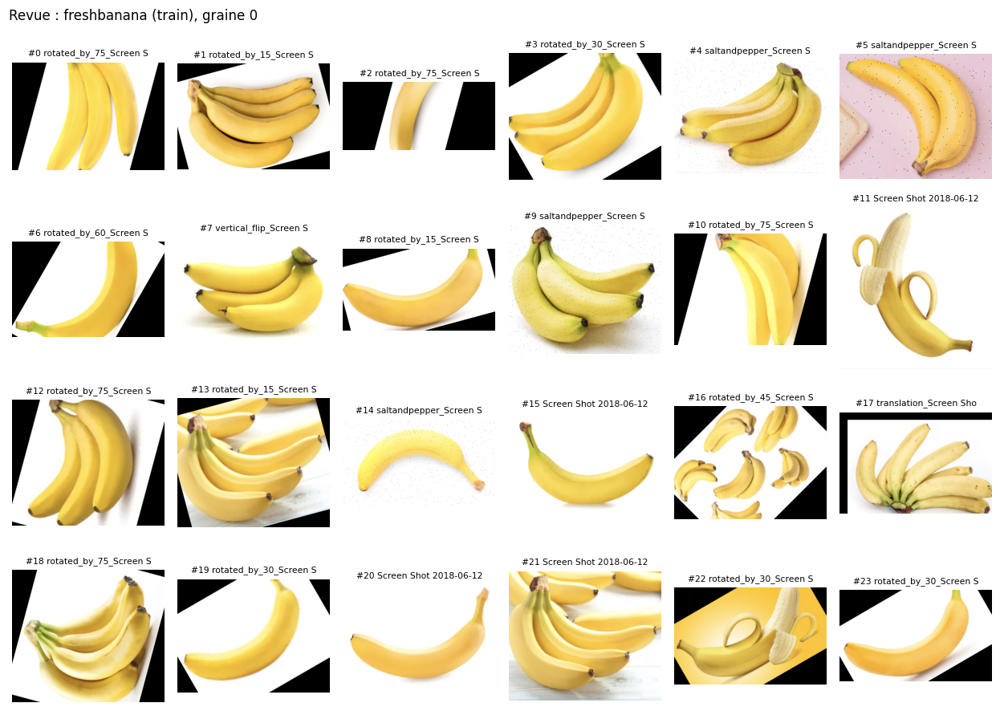

In [ ]:
# 👉 Inspecte une classe, puis note les cas ambigus avec leur numéro affiché.
vus = revue("freshbanana", n=24, graine=0)
# ajouter_cas(vus[3], "banane mûre tachetée", "taches brunes mais étiquetée saine")
# vus = revue("rottenoranges", n=24, graine=0)
# ajouter_cas(vus[7], "pourriture peu visible", "une seule petite tache")

ajouté : train/freshbanana/rotated_by_75_Screen Shot 2018-06-12 at 9.47.46 PM.png → fond ou éclairage trompeur
ajouté : train/freshbanana/saltandpepper_Screen Shot 2018-06-12 at 9.52.06 PM.png → fond ou éclairage trompeur
ajouté : train/freshbanana/Screen Shot 2018-06-12 at 10.04.54 PM.png → aspect atypique
ajouté : train/freshbanana/rotated_by_45_Screen Shot 2018-06-12 at 10.04.49 PM.png → plusieurs fruits
ajouté : train/freshbanana/rotated_by_30_Screen Shot 2018-06-12 at 9.45.46 PM.png → aspect atypique


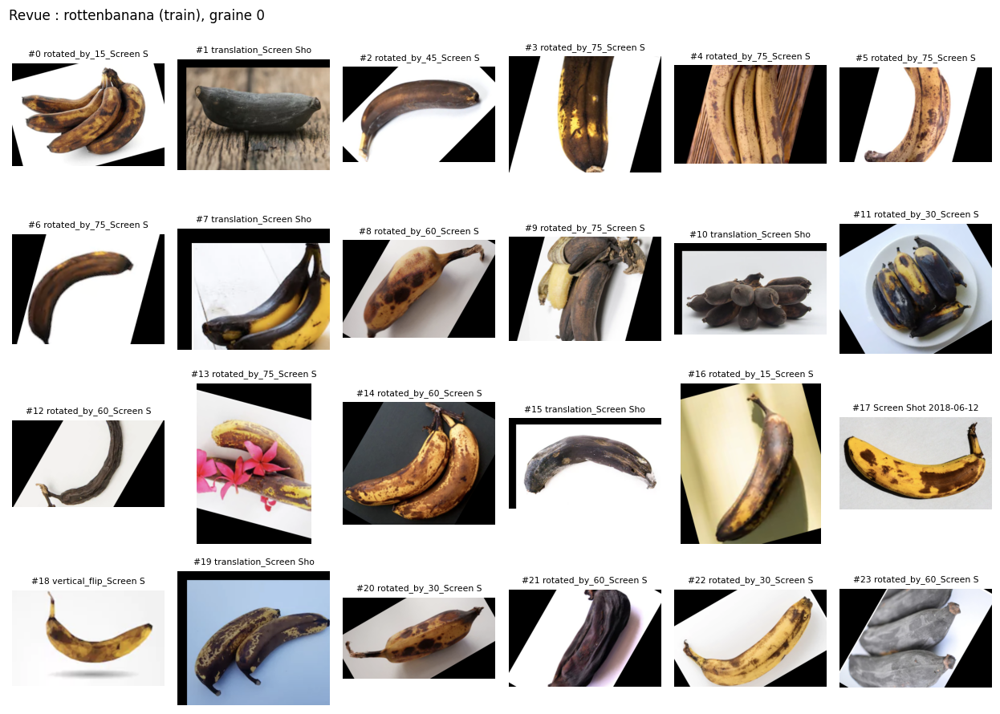

In [ ]:
ajouter_cas(vus[2],  "fond ou éclairage trompeur", "rotation 75° : surtout des coins noirs, fruit à peine visible")
ajouter_cas(vus[5],  "fond ou éclairage trompeur", "fond rose, peu courant dans le jeu")
ajouter_cas(vus[11], "aspect atypique", "banane à moitié épluchée")
ajouter_cas(vus[16], "plusieurs fruits", "plusieurs petites bananes éparpillées")
ajouter_cas(vus[22], "aspect atypique", "banane épluchée sur fond jaune")
vus = revue("rottenbanana", n=24, graine=0)

ajouté : train/rottenbanana/Screen Shot 2018-06-12 at 8.54.43 PM.png → banane mûre tachetée
ajouté : train/rottenbanana/vertical_flip_Screen Shot 2018-06-12 at 9.01.46 PM.png → banane mûre tachetée
ajouté : train/rottenbanana/rotated_by_30_Screen Shot 2018-06-12 at 8.47.14 PM.png → banane mûre tachetée
ajouté : train/rottenbanana/translation_Screen Shot 2018-06-12 at 9.09.29 PM.png → pourriture peu visible
ajouté : train/rottenbanana/rotated_by_75_Screen Shot 2018-06-12 at 8.58.13 PM.png → fond ou éclairage trompeur
ajouté : train/rottenbanana/rotated_by_60_Screen Shot 2018-06-12 at 9.20.07 PM.png → aspect atypique


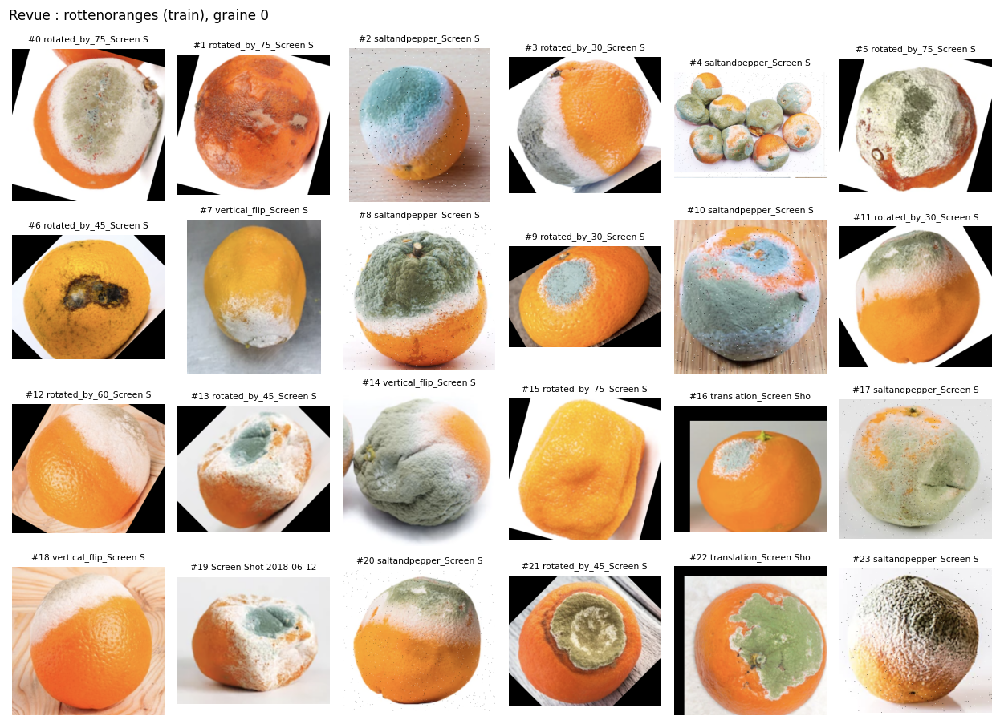

In [ ]:
ajouter_cas(vus[17], "banane mûre tachetée", "majoritairement jaune avec taches : pourrait passer pour saine")
ajouter_cas(vus[18], "banane mûre tachetée", "jaune avec quelques taches brunes")
ajouter_cas(vus[22], "banane mûre tachetée", "jaune tachetée, frontière sain/pourri floue")
ajouter_cas(vus[7],  "pourriture peu visible", "une banane encore à moitié jaune")
ajouter_cas(vus[13], "fond ou éclairage trompeur", "fleurs roses posées sur le fruit")
ajouter_cas(vus[23], "aspect atypique", "image en niveaux de gris : la couleur, indice principal, est absente")
vus = revue("rottenoranges", n=24, graine=0)

ajouté : train/rottenoranges/rotated_by_75_Screen Shot 2018-06-12 at 11.23.19 PM.png → pourriture peu visible
ajouté : train/rottenoranges/translation_Screen Shot 2018-06-12 at 11.34.13 PM.png → pourriture peu visible
ajouté : train/rottenoranges/rotated_by_45_Screen Shot 2018-06-12 at 11.19.22 PM.png → orange marquée / abîmée
ajouté : train/rottenoranges/rotated_by_75_Screen Shot 2018-06-12 at 11.40.36 PM.png → orange marquée / abîmée
ajouté : train/rottenoranges/saltandpepper_Screen Shot 2018-06-12 at 11.27.30 PM.png → plusieurs fruits


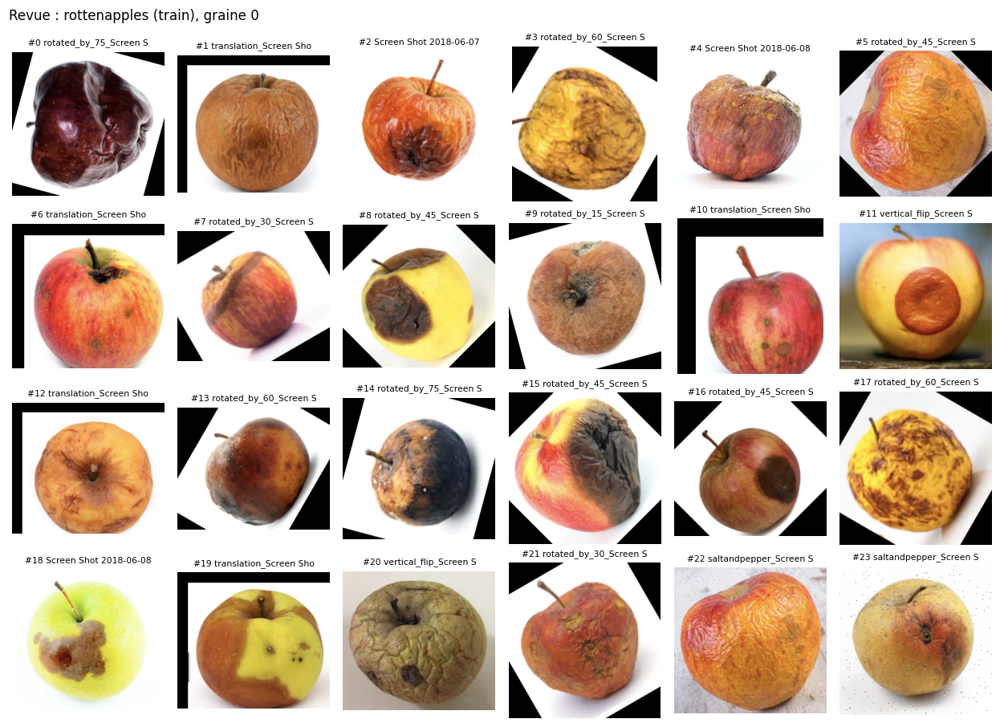

In [ ]:
ajouter_cas(vus[15], "pourriture peu visible", "légèrement ridée, sans moisissure visible : pourrait passer pour saine")
ajouter_cas(vus[16], "pourriture peu visible", "presque entièrement orange, petite tache de moisissure en haut")
ajouter_cas(vus[6],  "orange marquée / abîmée", "une seule tache sombre sur fond jaune")
ajouter_cas(vus[1],  "orange marquée / abîmée", "marques brunes sans moisissure")
ajouter_cas(vus[4],  "plusieurs fruits", "une dizaine d'oranges dans la même photo")
vus = revue("rottenapples", n=24, graine=0)

In [ ]:
ajouter_cas(vus[6],  "pomme légèrement meurtrie", "aspect presque sain, seulement de petites taches")
ajouter_cas(vus[10], "pomme légèrement meurtrie", "pomme rouge, quelques petites taches seulement")
ajouter_cas(vus[16], "pomme légèrement meurtrie", "saine sauf une tache brune")
ajouter_cas(vus[11], "fond ou éclairage trompeur", "fond extérieur flou, rare dans le jeu")

ajouté : train/rottenapples/translation_Screen Shot 2018-06-07 at 2.31.59 PM.png → pomme légèrement meurtrie
ajouté : train/rottenapples/translation_Screen Shot 2018-06-07 at 2.23.02 PM.png → pomme légèrement meurtrie
ajouté : train/rottenapples/rotated_by_45_Screen Shot 2018-06-08 at 2.48.09 PM.png → pomme légèrement meurtrie
ajouté : train/rottenapples/vertical_flip_Screen Shot 2018-06-08 at 2.26.34 PM.png → fond ou éclairage trompeur


In [ ]:
auto = []
for r in man[~man.lisible].itertuples():
    auto.append([r.chemin_relatif, "fichier illisible", r.raison_exclusion])
for f_id in fam_conflit:
    m = ok[ok.famille == f_id]
    for r in m.itertuples():
        auto.append([r.chemin_relatif, "étiquette douteuse",
                     f"famille {f_id} présente dans plusieurs classes : {fam.loc[f_id, 'classes']}"])
petites = man[man.lisible & (man[["largeur", "hauteur"]].min(axis=1) < 64)]
for r in petites.itertuples():
    auto.append([r.chemin_relatif, "image floue / très petite", f"{int(r.largeur)}×{int(r.hauteur)} px"])
j_auto = pd.DataFrame(auto, columns=COLS_J).assign(source="auto")
j_man = (pd.read_csv(JOURNAL_MANUEL, keep_default_na=False) if JOURNAL_MANUEL.exists()
         else pd.DataFrame(columns=COLS_J)).assign(source="manuel")
journal = pd.concat([j_auto, j_man], ignore_index=True).merge(
    man[["chemin_relatif", "classe", "partition", "famille", "split"]], on="chemin_relatif", how="left")
journal = journal[["chemin_relatif", "classe", "partition", "split", "famille", "source", "motif", "commentaire"]]
journal.to_csv(OUT / "journal_cas_ambigus.csv", index=False)
print(f"Journal : {len(journal)} entrées ({len(j_auto)} auto, {len(j_man)} manuelles)")
display(journal.groupby(["source", "motif"]).size().rename("nb") if len(journal) else "journal vide")

Journal : 74 entrées (54 auto, 20 manuelles)


source  motif                     
auto    étiquette douteuse            54
manuel  aspect atypique                3
        banane mûre tachetée           3
        fond ou éclairage trompeur     4
        orange marquée / abîmée        2
        plusieurs fruits               2
        pomme légèrement meurtrie      3
        pourriture peu visible         3
Name: nb, dtype: int64

## 12. Brouillon de la section « Données » du rapport

In [ ]:
eff_md = effectifs.copy()
rep_md = repartition.copy()
n_exclus_fuite = int((ok.raison_exclusion == "famille présente dans le test").sum())
n_exclus_conf = int((ok.raison_exclusion == "famille avec plusieurs classes").sum())
types_md5 = resume_md5.groupby("type").n.agg(["size", "sum"]) if len(resume_md5) else pd.DataFrame()
def t(typ, col="size"):
    return int(types_md5.loc[typ, col]) if typ in types_md5.index else 0

conf_txt = f", ainsi que {n_exclus_conf} images de familles multi-classes" if EXCLURE_CONFLITS and n_exclus_conf else ""
val_txt = (f"Les images restantes sont découpées avec `StratifiedGroupKFold` en {n_plis} plis (graine {SEED}) ; "
           f"le pli {PLI_RETENU} est retenu comme validation, car c'est le plus proche de {VAL_FRACTION:.0%} "
           f"dans chaque classe (écart maximal : {ECART_MAX:.1%}).")
if MODE_SPLIT == "test_kaggle":
    split_txt = (f"Conformément à la consigne, la partition de test officielle est conservée telle quelle. "
                 f"Nous retirons du train les {n_exclus_fuite} images dont la famille apparaît dans le test{conf_txt}. "
                 f"Comme la plupart des photos d'origine sont présentes des deux côtés, le train est fortement réduit : "
                 f"c'est le prix d'une évaluation sans fuite. " + val_txt)
else:
    split_txt = (f"Le découpage officiel fuyant massivement, nous l'avons refait entièrement par famille. "
                 f"Après retrait des familles multi-classes{conf_txt.replace(', ainsi que ', ' (') + ')' if conf_txt else ''}, "
                 f"un nouveau test d'environ {TEST_FRACTION:.0%} des images est tiré avec `StratifiedGroupKFold` "
                 f"(pli {PLI_TEST}, écart maximal {ECART_TEST:.1%}). " + val_txt)

texte = f"""## Données

### Source et structure
Nous utilisons le jeu public *Fruits fresh and rotten for classification* (S. R. Kalluri, Kaggle), organisé en dossiers `train/` et `test/` contenant chacun six classes : pomme, banane et orange, à l'état sain ou pourri. L'archive contient {len(COPIES)} copie(s) de l'arborescence ({"identiques" if COPIES_IDENTIQUES else "non identiques"}) ; nous n'en conservons qu'une (`{SOUS_DOSSIER_RACINE}`). Sur {len(df)} fichiers, {int(df.lisible.sum())} sont lisibles ; {len(df) - int(df.lisible.sum())} sont illisibles ou ignorés.

Les étiquettes numériques suivent l'ordre alphabétique des dossiers, comme l'infère Keras. Nous avons vérifié visuellement, sur un échantillon de chaque classe, que les images correspondent à leur dossier.

{md_table(correspondance, index=False)}

### Effectifs (images lisibles)
{md_table(eff_md)}

### Doublons et variantes proches
- **Doublons exacts (MD5)** : {N_MD5_GROUPES} groupes et {N_MD5_FICHIERS} fichiers, soit {N_MD5_REDONDANTS} copies en trop. Parmi ces groupes, {t("même partition")} sont internes à une partition, {t("train ↔ test")} sont partagés entre train et test et {t("conflit de classe")} relient des classes différentes.
- **Variantes proches (pHash 64 bits)** : en considérant deux images comme proches si leur distance de Hamming est ≤ {PHASH_SEUIL_MEME_CLASSE} pour deux images de la même classe et ≤ {PHASH_SEUIL} entre classes différentes{" (sur les 8 orientations)" if INVARIANCE_DIEDRALE else ""}, nous trouvons {N_PAIRES_PROCHES} paires en plus des doublons exacts{f" (les {N_COINS_NOIRS} copies tournées ou translatées sont exclues de cette comparaison, car leurs coins noirs créent de fausses ressemblances ; elles sont rattachées par leur nom de fichier)" if IGNORER_COINS_NOIRS else ""}. {N_PAIRES_TRAIN_TEST} de ces paires relient train et test, et {N_PAIRES_CONFLIT} relient des classes différentes. Les seuils ont été fixés par contrôle visuel : à d = 6, la majorité des paires sont encore de vraies copies, mais les faux liens observés relient toujours des classes différentes, d'où un seuil plus strict entre classes. Un faux lien ne fait qu'exclure quelques images de plus du train, alors qu'un lien manqué crée une fuite vers le test : nous privilégions donc des seuils plutôt larges.
- **Augmentations repérées par le nom de fichier** : {N_AUG_PREFIXE} fichiers portent un préfixe d'augmentation (par exemple `rotated_by_15_`). {"Ils sont rattachés à leur image d'origine." if UTILISER_NOMS_FICHIERS else "Le rattachement par nom était désactivé."} Le jeu ne contient en réalité que **{N_PHOTOS_ORIGINE} photos d'origine**, chacune déclinée jusqu'à 9 fois (rotations de 15 à 75°, retournement, translation, bruit « sel et poivre »). Le découpage officiel a été fait au niveau des images augmentées et non des photos : **{N_PHOTOS_COMMUNES} photos d'origine se retrouvent à la fois dans le train et dans le test**, ce qui gonflerait artificiellement les scores sur le test officiel.
- **Familles** : en réunissant ces liens par union-find, nous obtenons {N_FAMILLES} familles, dont {N_FAM_MULTI} contiennent plus d'une image (taille maximale : {int(fam.taille.max())}). {N_FAM_TT} familles se trouvent à la fois dans le train et dans le test, et {N_FAM_CONFLIT} mélangent plusieurs classes.

### Découpage train / validation / test
{split_txt} Nous avons vérifié qu'aucune famille ni aucun MD5 n'est partagé entre deux ensembles.

{md_table(rep_md)}

### Cas ambigus
Le journal (`journal_cas_ambigus.csv`) compte {len(journal)} entrées : {len(j_auto)} détectées automatiquement (fichiers illisibles, étiquettes douteuses, images très petites) et {len(j_man)} relevées manuellement (bananes mûres tachetées, oranges marquées, etc.). Il sert de référence pour l'analyse des erreurs.

*Figures : `effectifs_classes.png`, `exemples_train.png`, `tailles_familles.png`, `split_final.png`.*
"""
(OUT / "rapport_section_donnees.md").write_text(texte, encoding="utf-8")
display(Markdown(texte))

## Données

### Source et structure
Nous utilisons le jeu public *Fruits fresh and rotten for classification* (S. R. Kalluri, Kaggle), organisé en dossiers `train/` et `test/` contenant chacun six classes : pomme, banane et orange, à l'état sain ou pourri. L'archive contient 2 copie(s) de l'arborescence (identiques) ; nous n'en conservons qu'une (`dataset`). Sur 13599 fichiers, 13599 sont lisibles ; 0 sont illisibles ou ignorés.

Les étiquettes numériques suivent l'ordre alphabétique des dossiers, comme l'infère Keras. Nous avons vérifié visuellement, sur un échantillon de chaque classe, que les images correspondent à leur dossier.

| label | dossier | espece | etat |
|---|---|---|---|
| 0 | freshapples | pomme | sain |
| 1 | freshbanana | banane | sain |
| 2 | freshoranges | orange | sain |
| 3 | rottenapples | pomme | pourri |
| 4 | rottenbanana | banane | pourri |
| 5 | rottenoranges | orange | pourri |

### Effectifs (images lisibles)
| classe | train | test | total |
|---|---|---|---|
| freshapples | 1693 | 395 | 2088 |
| freshbanana | 1581 | 381 | 1962 |
| freshoranges | 1466 | 388 | 1854 |
| rottenapples | 2342 | 601 | 2943 |
| rottenbanana | 2224 | 530 | 2754 |
| rottenoranges | 1595 | 403 | 1998 |
| TOTAL | 10901 | 2698 | 13599 |

### Doublons et variantes proches
- **Doublons exacts (MD5)** : 0 groupes et 0 fichiers, soit 0 copies en trop. Parmi ces groupes, 0 sont internes à une partition, 0 sont partagés entre train et test et 0 relient des classes différentes.
- **Variantes proches (pHash 64 bits)** : en considérant deux images comme proches si leur distance de Hamming est ≤ 6 pour deux images de la même classe et ≤ 4 entre classes différentes, nous trouvons 1827 paires en plus des doublons exacts (les 9066 copies tournées ou translatées sont exclues de cette comparaison, car leurs coins noirs créent de fausses ressemblances ; elles sont rattachées par leur nom de fichier). 587 de ces paires relient train et test, et 3 relient des classes différentes. Les seuils ont été fixés par contrôle visuel : à d = 6, la majorité des paires sont encore de vraies copies, mais les faux liens observés relient toujours des classes différentes, d'où un seuil plus strict entre classes. Un faux lien ne fait qu'exclure quelques images de plus du train, alors qu'un lien manqué crée une fuite vers le test : nous privilégions donc des seuils plutôt larges.
- **Augmentations repérées par le nom de fichier** : 12088 fichiers portent un préfixe d'augmentation (par exemple `rotated_by_15_`). Ils sont rattachés à leur image d'origine. Le jeu ne contient en réalité que **1511 photos d'origine**, chacune déclinée jusqu'à 9 fois (rotations de 15 à 75°, retournement, translation, bruit « sel et poivre »). Le découpage officiel a été fait au niveau des images augmentées et non des photos : **1310 photos d'origine se retrouvent à la fois dans le train et dans le test**, ce qui gonflerait artificiellement les scores sur le test officiel.
- **Familles** : en réunissant ces liens par union-find, nous obtenons 1422 familles, dont 1422 contiennent plus d'une image (taille maximale : 54). 1240 familles se trouvent à la fois dans le train et dans le test, et 1 mélangent plusieurs classes.

### Découpage train / validation / test
Conformément à la consigne, la partition de test officielle est conservée telle quelle. Nous retirons du train les 9245 images dont la famille apparaît dans le test. Comme la plupart des photos d'origine sont présentes des deux côtés, le train est fortement réduit : c'est le prix d'une évaluation sans fuite. Les images restantes sont découpées avec `StratifiedGroupKFold` en 5 plis (graine 42) ; le pli 1 est retenu comme validation, car c'est le plus proche de 20% dans chaque classe (écart maximal : 3.1%). Nous avons vérifié qu'aucune famille ni aucun MD5 n'est partagé entre deux ensembles.

| classe | train | val | test | exclu | % val |
|---|---|---|---|---|---|
| freshapples | 198 | 54 | 395 | 1441 | 21.4 |
| freshbanana | 216 | 54 | 381 | 1311 | 20.0 |
| freshoranges | 225 | 54 | 388 | 1187 | 19.4 |
| rottenapples | 180 | 54 | 601 | 2108 | 23.1 |
| rottenbanana | 333 | 72 | 530 | 1819 | 17.8 |
| rottenoranges | 171 | 45 | 403 | 1379 | 20.8 |
| TOTAL | 1323 | 333 | 2698 | 9245 | 20.1 |

### Cas ambigus
Le journal (`journal_cas_ambigus.csv`) compte 74 entrées : 54 détectées automatiquement (fichiers illisibles, étiquettes douteuses, images très petites) et 20 relevées manuellement (bananes mûres tachetées, oranges marquées, etc.). Il sert de référence pour l'analyse des erreurs.

*Figures : `effectifs_classes.png`, `exemples_train.png`, `tailles_familles.png`, `split_final.png`.*


## 13. Récupérer les sorties

In [ ]:
import shutil
archive = shutil.make_archive("sorties_personne1", "zip", OUT)
print("Archive :", archive)
print(sorted(p.relative_to(OUT).as_posix() for p in OUT.rglob("*") if p.is_file()))
if "google.colab" in sys.modules and not SAUVER_SUR_DRIVE:
    from google.colab import files
    files.download(archive)

Archive : /content/sorties_personne1.zip
['caracteristiques.csv', 'doublons_exacts.csv', 'effectifs.csv', 'familles.csv', 'figures/effectifs_classes.png', 'figures/exemples_test.png', 'figures/exemples_train.png', 'figures/split_final.png', 'figures/tailles_familles.png', 'journal_cas_ambigus.csv', 'journal_manuel.csv', 'labels.json', 'manifeste.csv', 'paires_proches.csv', 'rapport_section_donnees.md', 'split_config.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>